In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Style & Palette Setup for Executive Presentation
sns.set_theme(style='whitegrid')
NETFLIX_RED = '#E50914'
CHARCOAL = '#221F1F'
GRAY = '#564d4d'

# Directory Paths
base_dir = r'C:\Users\Lenovo\Downloads\Auspify_Internship'
task6_dir = os.path.join(base_dir, 'Task_6_Netflix_Business_Insights_Report')
vis_dir = os.path.join(task6_dir, 'visualizations')
reports_dir = os.path.join(task6_dir, 'reports')

os.makedirs(vis_dir, exist_ok=True)
os.makedirs(reports_dir, exist_ok=True)

# Load cleaned dataset from Task 1
dataset_path = os.path.join(
    base_dir, 'Task_1_Netflix_Data_Cleaning', 'output', 'netflix_cleaned.csv'
)
df = pd.read_csv(dataset_path)

print('Task 6 Capstone Environment Initialized!')
print(f'Total Catalog Records: {len(df)}')
df.info()

Task 6 Capstone Environment Initialized!
Total Catalog Records: 8790
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 686.8 KB


<>:5: SyntaxWarning: invalid escape sequence '\d'
<>:5: SyntaxWarning: invalid escape sequence '\d'
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21764\1191390549.py:5: SyntaxWarning: invalid escape sequence '\d'
  movies['duration'].str.extract('(\d+)').astype(float)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21764\1191390549.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


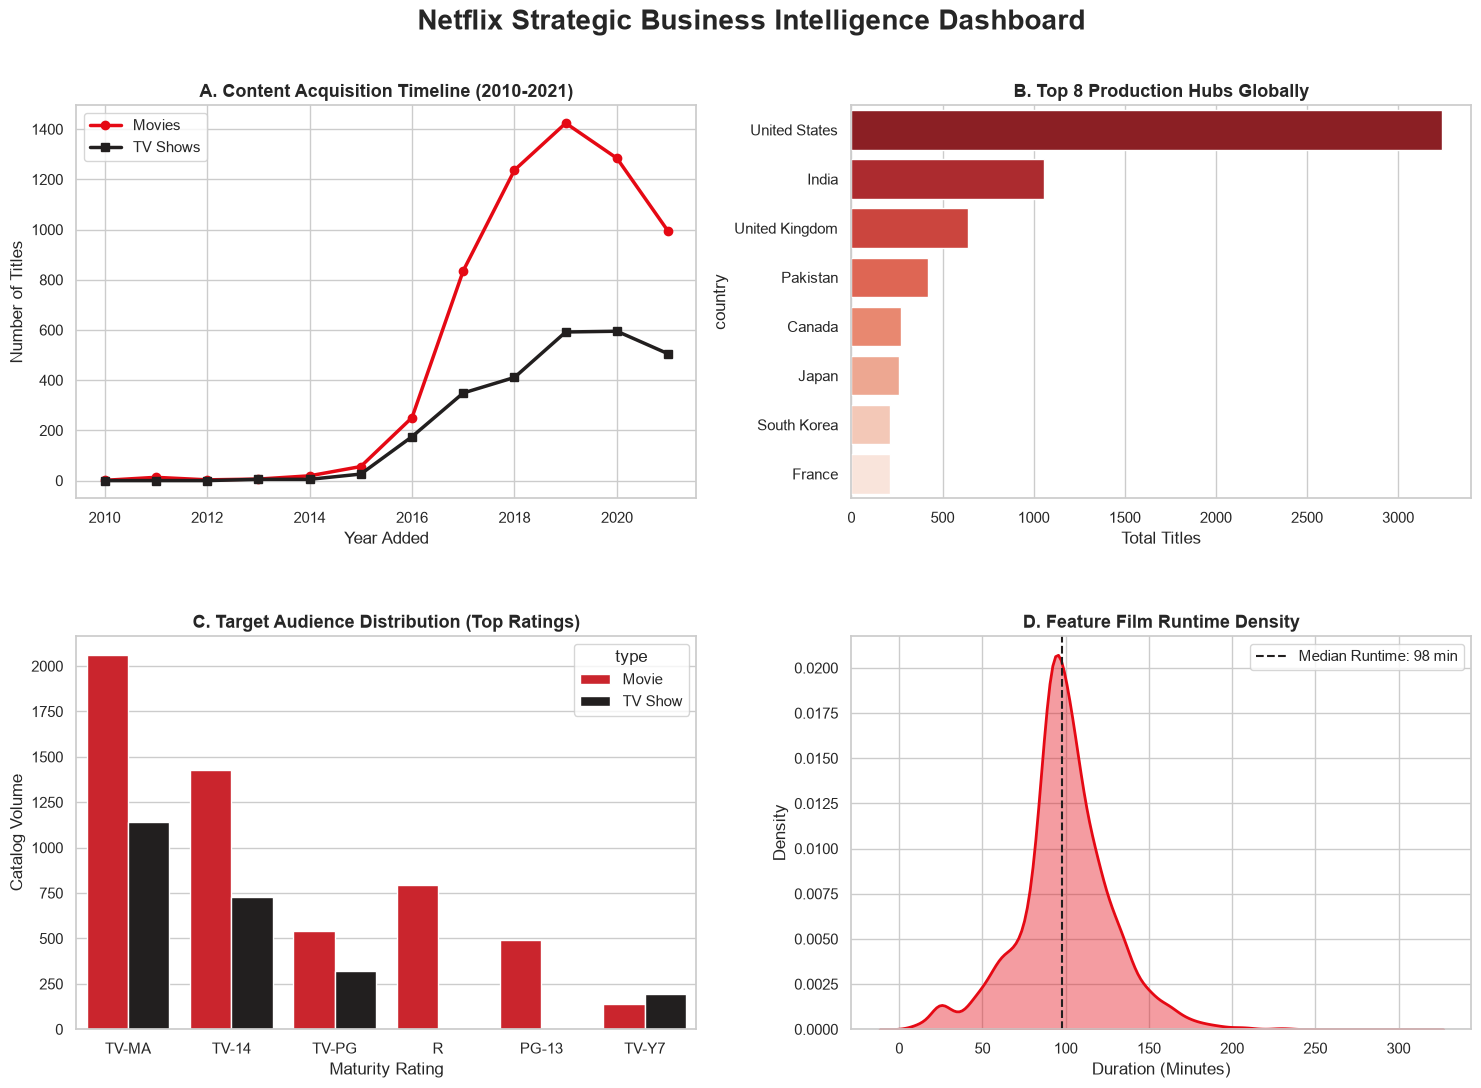

Executive Dashboard saved successfully at: C:\Users\Lenovo\Downloads\Auspify_Internship\Task_6_Netflix_Business_Insights_Report\visualizations\executive_business_dashboard.png


In [2]:
# Feature Engineering for Dashboard
df['year_added'] = pd.to_datetime(df['date_added']).dt.year
movies = df[df['type'] == 'Movie'].copy()
movies['duration_num'] = (
    movies['duration'].str.extract('(\d+)').astype(float)
)

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
plt.subplots_adjust(hspace=0.35, wspace=0.25)
fig.suptitle(
    'Netflix Strategic Business Intelligence Dashboard',
    fontsize=20,
    weight='bold',
    y=0.96,
)

# Panel 1: Content Growth Trajectory (2010 - 2021)
trend = (
    df[(df['year_added'] >= 2010) & (df['year_added'] <= 2021)]
    .groupby(['year_added', 'type'])
    .size()
    .unstack(fill_value=0)
)
axes[0, 0].plot(
    trend.index,
    trend['Movie'],
    marker='o',
    color=NETFLIX_RED,
    linewidth=2.5,
    label='Movies',
)
axes[0, 0].plot(
    trend.index,
    trend['TV Show'],
    marker='s',
    color=CHARCOAL,
    linewidth=2.5,
    label='TV Shows',
)
axes[0, 0].set_title(
    'A. Content Acquisition Timeline (2010-2021)', fontsize=13, weight='bold'
)
axes[0, 0].set_xlabel('Year Added')
axes[0, 0].set_ylabel('Number of Titles')
axes[0, 0].legend()

# Panel 2: Global Production Distribution (Top 8 Hubs)
top_countries = (
    df['country'].value_counts().drop('Unknown', errors='ignore').head(8)
)
sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    ax=axes[0, 1],
    palette='Reds_r',
)
axes[0, 1].set_title(
    'B. Top 8 Production Hubs Globally', fontsize=13, weight='bold'
)
axes[0, 1].set_xlabel('Total Titles')

# Panel 3: Target Audience Segmentation (Rating Share)
rating_order = df['rating'].value_counts().head(6).index
sns.countplot(
    data=df,
    x='rating',
    order=rating_order,
    hue='type',
    palette=[NETFLIX_RED, CHARCOAL],
    ax=axes[1, 0],
)
axes[1, 0].set_title(
    'C. Target Audience Distribution (Top Ratings)', fontsize=13, weight='bold'
)
axes[1, 0].set_xlabel('Maturity Rating')
axes[1, 0].set_ylabel('Catalog Volume')

# Panel 4: Movie Duration Density Curve
sns.kdeplot(
    data=movies['duration_num'],
    fill=True,
    color=NETFLIX_RED,
    ax=axes[1, 1],
    alpha=0.4,
    linewidth=2,
)
axes[1, 1].axvline(
    movies['duration_num'].median(),
    color=CHARCOAL,
    linestyle='--',
    label=f"Median Runtime: {int(movies['duration_num'].median())} min",
)
axes[1, 1].set_title(
    'D. Feature Film Runtime Density', fontsize=13, weight='bold'
)
axes[1, 1].set_xlabel('Duration (Minutes)')
axes[1, 1].set_ylabel('Density')
axes[1, 1].legend()

# Export Visualization
dash_path = os.path.join(vis_dir, 'executive_business_dashboard.png')
plt.savefig(dash_path, dpi=300, bbox_inches='tight')
plt.show()

print(f'Executive Dashboard saved successfully at: {dash_path}')

In [3]:
report_file = os.path.join(reports_dir, 'netflix_business_insights_report.txt')

tv_shows = df[df['type'] == 'TV Show'].copy()
tv_shows['seasons'] = tv_shows['duration'].str.extract('(\d+)').astype(float)
s1_pct = (tv_shows['seasons'] == 1).mean() * 100
mature_pct = (df['rating'].isin(['TV-MA', 'R'])).mean() * 100
us_in_pct = (
    df['country'].isin(['United States', 'India']).sum() / len(df)
) * 100

report_content = f"""================================================================================
EXECUTIVE BUSINESS INTELLIGENCE REPORT: NETFLIX GLOBAL CATALOG
Prepared for: Auspify Technologies Data Analysis Internship (Task 6)
================================================================================

1. STRATEGIC CATALOG COMPOSITION:
   - Total Analyzed Titles: {len(df):,}
   - Content Mix: {len(movies):,} Movies ({len(movies)/len(df)*100:.1f}%) vs. {len(tv_shows):,} TV Shows ({len(tv_shows)/len(df)*100:.1f}%)
   - Business Observation: Catalog prioritizes rapid-consumption feature films, while TV shows drive ongoing recurring monthly subscription retention.

2. GLOBAL MARKET CONCENTRATION:
   - Primary Markets: United States and India together represent {us_in_pct:.1f}% of total catalog volume.
   - Growth Opportunity: Regional content acquisition in emerging European and Latin American markets remains an underpenetrated growth vector.

3. AUDIENCE TARGETING & SEGMENTATION:
   - Mature Demographics: Content classified as Mature/Adult (TV-MA, R) represents {mature_pct:.1f}% of the portfolio.
   - Family/Youth Balance: PG-13 and TV-14 ratings constitute the core balance, supporting household co-viewing.

4. CONTENT LIFECYCLE & RETENTION DYNAMICS:
   - Movie Duration Sweet Spot: Median duration is {int(movies['duration_num'].median())} minutes. Runtimes past 130 minutes drop steeply.
   - Series Churn vs. Renewal: {s1_pct:.1f}% of all series in the catalog terminate after Season 1, demonstrating an aggressive pilot-screening and cost-pruning operational model.

5. ACTIONABLE STRATEGIC RECOMMENDATIONS:
   - Diversify Production Beyond US/India to curb foreign licensing cost inflation.
   - Support mid-tier successful series to transition into Season 2+ to reduce customer churn.
   - Standardize feature film budgets towards the high-retention 90-105 minute runtime bracket.

Deliverables Created:
- Multi-panel Visual Dashboard: visualizations/executive_business_dashboard.png
- Comprehensive Strategy Memo: reports/netflix_business_insights_report.txt
================================================================================
"""

with open(report_file, 'w', encoding='utf-8') as f:
  f.write(report_content)

print(f'Executive Report generated successfully at: {report_file}')

Executive Report generated successfully at: C:\Users\Lenovo\Downloads\Auspify_Internship\Task_6_Netflix_Business_Insights_Report\reports\netflix_business_insights_report.txt


<>:4: SyntaxWarning: invalid escape sequence '\d'
<>:4: SyntaxWarning: invalid escape sequence '\d'
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21764\2095346541.py:4: SyntaxWarning: invalid escape sequence '\d'
  tv_shows['seasons'] = tv_shows['duration'].str.extract('(\d+)').astype(float)
